In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from bike_sharing_data import get_bike_sharing

X_train, X_test, y_train, y_test = get_bike_sharing()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (13903, 12)
Testing data: (3476, 12)


In [3]:
import numpy as np
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert target into 1D arrays
y_train_nn = np.asarray(y_train).ravel()
y_test_nn = np.asarray(y_test).ravel()

print("Feature scaling completed!")

Feature scaling completed!


In [4]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [5]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(1, activation='linear')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
from tqdm.keras import TqdmCallback

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train_nn,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[
        early_stop, 
        TqdmCallback(verbose=1)
    ],
    verbose=0 
# Without TqdmCallback, Keras displays its own progress bar for each epoch.
# TqdmCallback displays a single progress bar to track the overall training progress across all epochs.

# verbose=0: Displays the progress bar without additional epoch-end output.
# verbose=1: Displays additional epoch-end information, such as training metrics.
)

print("Neural Network Model training completed!")

100%|██████████| 100/100 [01:53<00:00,  1.14s/epoch, loss=1.03e+4, mae=66.1, val_loss=8.36e+3, val_mae=56.6]

Neural Network Model training completed!


In [7]:
y_train_pred = model.predict(X_train_scaled).ravel()

y_test_pred = model.predict(X_test_scaled).ravel()

435/435 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Evaluation on testing data

mae = mean_absolute_error(y_test_nn, y_test_pred)

mse = mean_squared_error(y_test_nn, y_test_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test_nn, y_test_pred)

print("Neural Network Model Evaluation on Test Data")
print("----------------------------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Neural Network Model Evaluation on Test Data
----------------------------------------------
MAE : 56.31547927856445
MSE : 7487.04931640625
RMSE: 86.52773726618679
R2 Score: 0.763557493686676


In [9]:
train_r2 = r2_score(y_train_nn, y_train_pred)

# Compare training and testing performance
print("Training R2:", train_r2)
print("Testing R2:", r2)

Training R2: 0.7794438004493713
Testing R2: 0.763557493686676


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

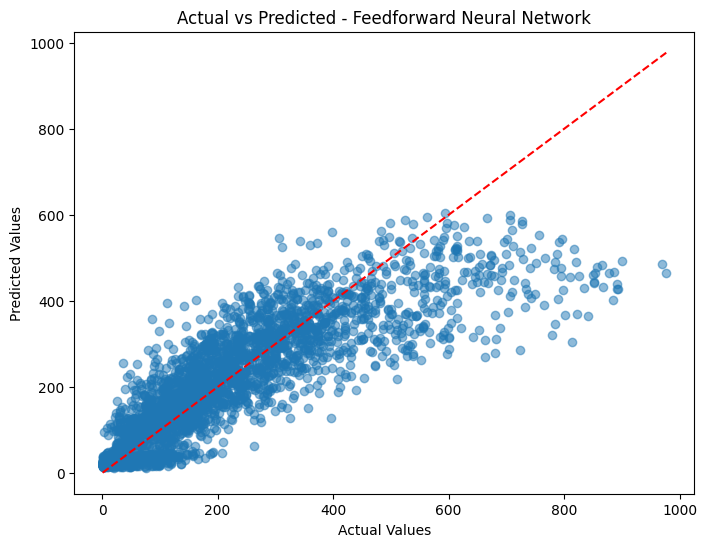

In [11]:
# Plot: Actual vs Predicted values

plt.figure(figsize=(8, 6))

plt.scatter(y_test_nn, y_test_pred, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test_nn.min(), y_test_nn.max()],
    [y_test_nn.min(), y_test_nn.max()],
    'r--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - Feedforward Neural Network")

plt.show()

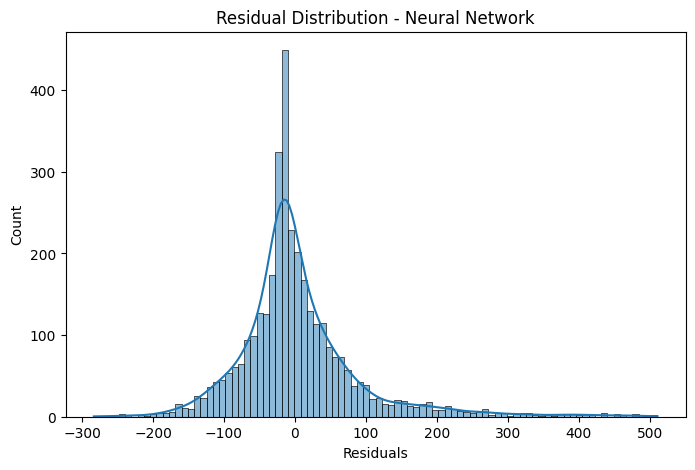

In [12]:
# Residual = Actual value - Predicted value

residuals = y_test_nn - y_test_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Residual Distribution - Neural Network")

plt.show()

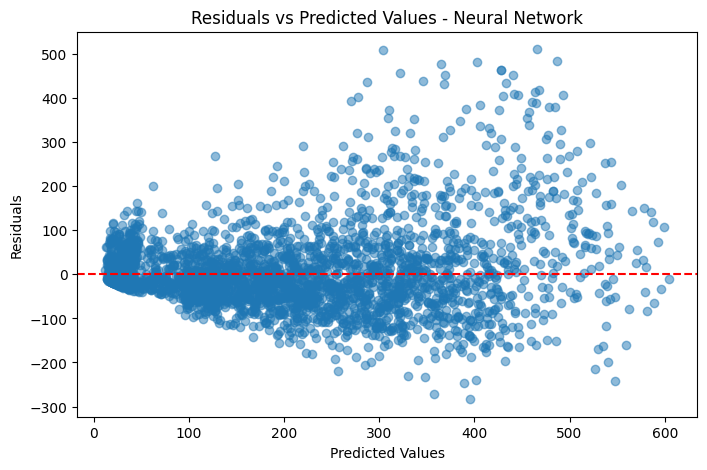

In [13]:
# Plot: Residuals vs Predicted values

plt.figure(figsize=(8, 5))

plt.scatter(y_test_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values - Neural Network")

plt.show()

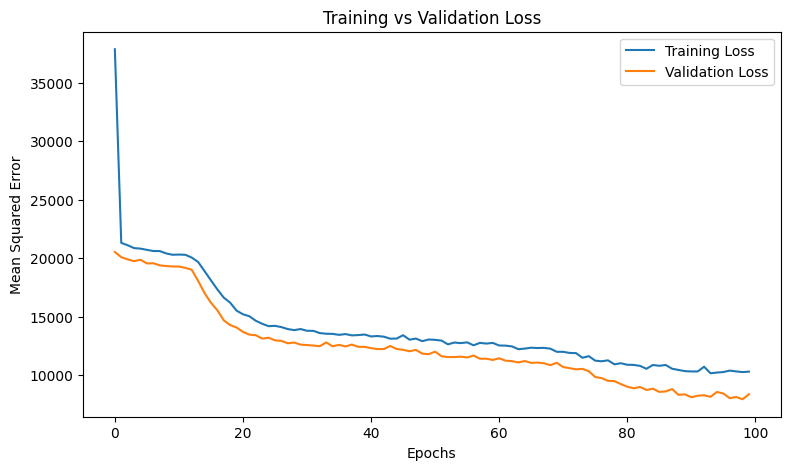

In [14]:
# Plot: Training and validation loss

plt.figure(figsize=(9, 5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")

plt.title("Training vs Validation Loss")

plt.legend()

plt.show()

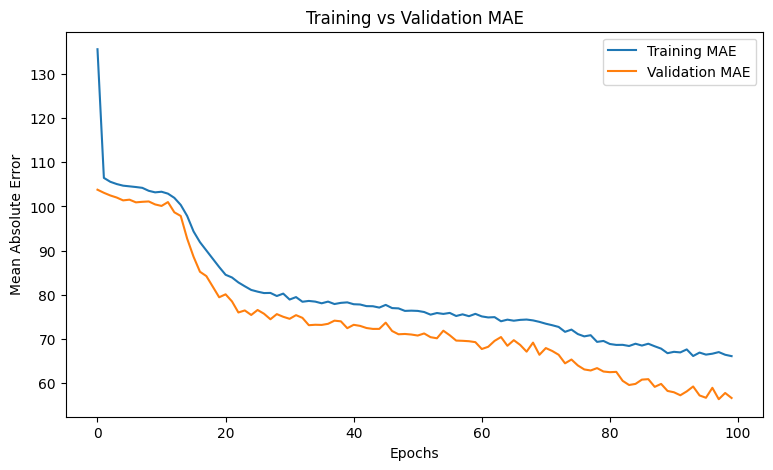

In [15]:
# Plot: Training and validation MAE

plt.figure(figsize=(9, 5))

plt.plot(history.history['mae'], label='Training MAE')

plt.plot(history.history['val_mae'], label='Validation MAE')

plt.xlabel("Epochs")
plt.ylabel("Mean Absolute Error")

plt.title("Training vs Validation MAE")

plt.legend()

plt.show()